Public-contract revision 2026-10-29

V1 demanded identity with a weakly identifiable finite optimizer parameter estimate; v2 independently validates all GRE signal/parameter identities and per-case squared-error budgets. An independently fitted 200000-second transit alternative passes; physically valid zero-flow controls fail. No actual truth exists. Full source algorithm and arrays unchanged. The earlier reference-comparison tables are historical v1 diagnostics, not current acceptance criteria. Current standalone Judge metrics are authoritative.

# Problem
## Filtration and tubular transit from measured renal contrast MRI
Dynamic MRI follows contrast entering the blood and accumulating in the kidneys. Infer plasma flow $F_p$, plasma volume fraction $v_p$, filtration-to-plasma-flow ratio $f$ and tubular transit time $T_t$ from measured aortic and whole-kidney curves.

These 228 kidneys from 114 scans/100 participants are the complete released KRUK cohort. The independent isotope measurements assess derived clinical filtration, but do **not** provide ground truth for the four primary parameters. Original-author execution provides the method reference. Fresh results below are actively computed with local mathematics. The released cohort differs from the historical paper's 127 studies; no reproduction of that full historical cohort is claimed.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from IPython.display import display,Markdown
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data,case_data
from src.solvers import reconstruct,fit_case,LOWER,UPPER
from src.physics_model import predict
from src.visualization import clinical_statistics,bland_altman
d=load_data(root/'data/raw_data.npz')
up=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print('Original reference keys:',up.files)
plt.rcParams.update({'font.size':9,'figure.dpi':110})

Original reference keys: ['upstream_parameters', 'upstream_signal', 'isotope_gfr_source', 'upstream_gfr', 'linear_gfr', 'linear_signal', 'linear_parameters', 'linear_delay_gfr', 'linear_delay_signal', 'linear_delay_parameters', 'ss_literature_gfr', 'ss_literature_signal', 'ss_literature_parameters']


# Data
The author distributes processed regions of interest, not raw instrument images. Each scan contains an aortic input and left/right kidney signal with per-scan repetition time, flip angle, baseline count, volume and field strength. Independent precontrast tissue T1 is used where available, otherwise literature calibration. Variable-length curves are padded only for storage; padding never enters fitting.

Acquisition used 1 T and 3 T contrast MRI. All data and calibration are kept in original temporal order. No isotope target enters fitting or calibration. The isotope column's unit label conflicts with the author's executable example: the example treats stored values as mL/s and multiplies by 60. We explicitly follow that convention for comparison and retain the source values privately. It remains a provenance limitation, not a silent correction.

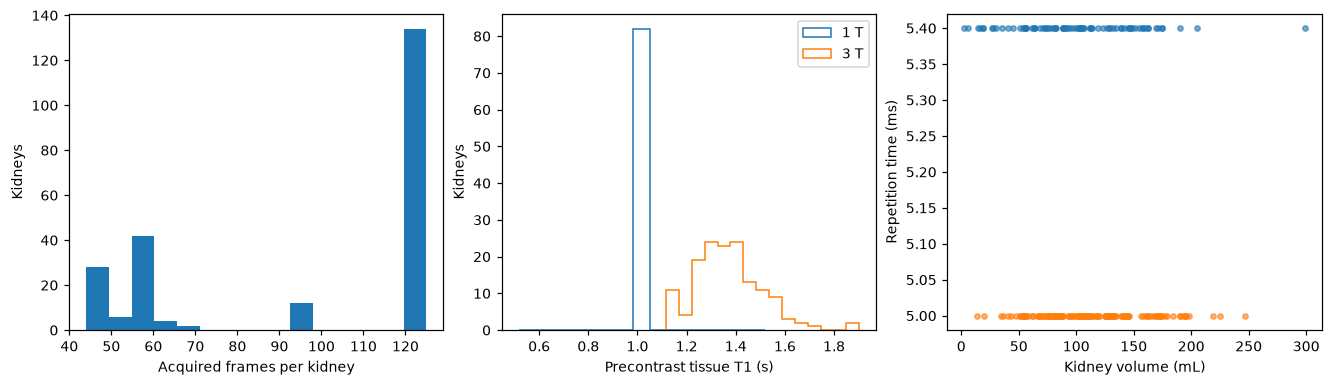

Kidneys: 228 scans: 114 participants: 100
Measured tissue T1 count: 144 post-scan kidneys: 34


In [2]:
field=d['field_strength'][0]; ids=d['case_identifiers'][0]
fig,axes=plt.subplots(1,3,figsize=(12,3.4),layout='constrained')
axes[0].hist(d['lengths'][0],bins=15);axes[0].set(xlabel='Acquired frames per kidney',ylabel='Kidneys')
for f in [1,3]:
 m=field==f;axes[1].hist(d['tissue_t1'][0,m],bins=15,histtype='step',label=f'{f} T')
 axes[2].scatter(d['volume'][0,m],d['tr'][0,m]*1000,s=12,alpha=.6,label=f'{f} T')
axes[1].set(xlabel='Precontrast tissue T1 (s)',ylabel='Kidneys');axes[1].legend()
axes[2].set(xlabel='Kidney volume (mL)',ylabel='Repetition time (ms)');plt.show()
print('Kidneys:',len(field),'scans:',len(np.unique(ids[:,:2],axis=0)),'participants:',len(np.unique(ids[:,0])))
print('Measured tissue T1 count:',int(d['measured_t1'].sum()),'post-scan kidneys:',int(ids[:,1].sum()))

# Physics
The spoiled steady-state signal at longitudinal relaxation rate $R$ is
$$S=A\sin\alpha\frac{1-\exp(-\mathrm{TR}R)}{1-\cos\alpha\exp(-\mathrm{TR}R)},\qquad R=1/T_{10}+r_1(C_p+C_t).$$
Here $A$ is the baseline-calibrated scale, $\alpha$ flip angle, TR repetition time in seconds, $T_{10}$ precontrast relaxation time, $r_1$ relaxivity in inverse seconds per molar, and $C_p,C_t$ tissue-normalized plasma/tubular tracer concentrations in molar. Inverting the same signal relation in the aorta gives blood concentration; divide by $1-H$, with haematocrit $H=0.45$, to obtain plasma input $c_a$.

With filtration flow $F_t=fF_p$ and plasma transit $T_p=v_p/(F_p+F_t)$,
$$\dot C_p=F_pc_a-C_p/T_p,\qquad \dot C_t=F_tC_p/v_p-C_t/T_t.$$
Both compartments start empty. Flow has units mL/s/mL tissue; fractions are dimensionless and transit seconds. The ratio $f$ differs from extraction probability $f/(1+f)$. Derived single-kidney filtration is $60F_pfV$ mL/min, for kidney volume $V$ in mL. Signal calibration, sampling and weak washout can make different parameter combinations nearly indistinguishable.

# Method
Each compartment is evaluated using an exponential convolution with piecewise-linear sampled input. For interval $x=\Delta t/T$, input samples $J_i$, normalized convolution $g_i$, and $E=\exp(-x)$:
$$g_{i+1}=Eg_i+J_i(1-E)+(J_{i+1}-J_i)(x-1+E)/x,\qquad g_0=0.$$
Multiply by transit $T$ to get concentration. Applying this twice preserves the original sampled-compartment approximation. The local inverse minimizes unweighted squared magnitude residuals with bounded trust-region reflective least squares, initialized at $(.02,.15,.1,120)$. Bounds are $0\leq F_p\leq.05$, $0\leq v_p,f\leq.3$, $T_t\geq30$ s. There is no regularizer or target-derived prior.

Actively fit all 228 kidneys under four model/calibration assumptions: primary nonlinear signal with measured T1 where available; nonlinear with literature T1; linear signal with literature T1; linear with a fitted 0–3 s arterial delay. These are modern author-code comparisons, not the historical paper's numerical results.

In [3]:
start=time.perf_counter();fresh,diag=reconstruct(d);runtime=time.perf_counter()-start
variants={'measured':fresh}
for name in ['ss_literature','linear','linear_delay']:variants[name]=reconstruct(d,name)[0]
p=fresh['reconstruction'][0];s=fresh['signal'][0]
print(f'Primary fresh reconstruction {runtime:.3f} s; all four complete fits {time.perf_counter()-start:.3f} s')

Primary fresh reconstruction 3.887 s; all four complete fits 21.461 s


# Results
## Original implementation parity and measured fits
The original was executed on these exact 228 observation curves before extraction. It is a method comparison, not physiological truth. All observations, including poor fits and extreme transit estimates, remain included.

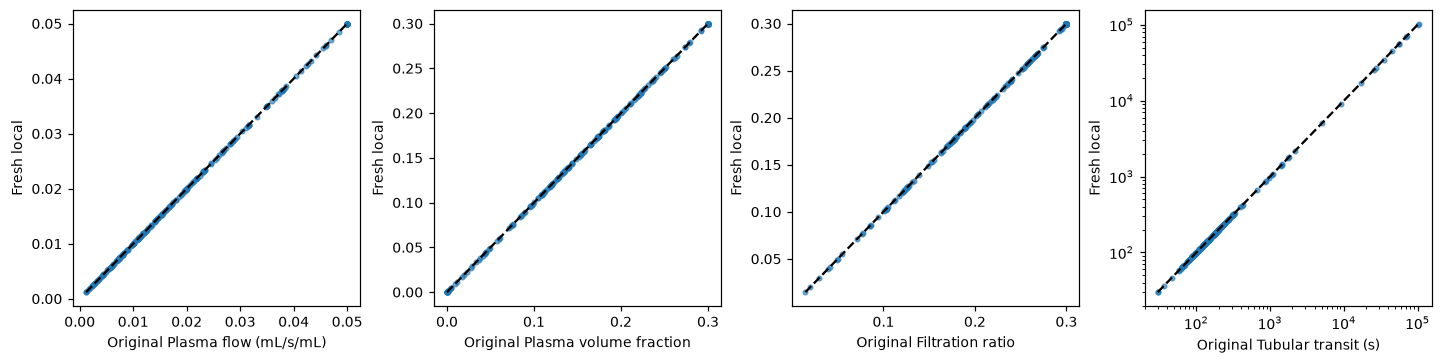

Primary parameter maximum absolute differences: [0. 0. 0. 0.]
Observed relative L2 residual median/max: 0.04990531187515705 0.16258405305627424


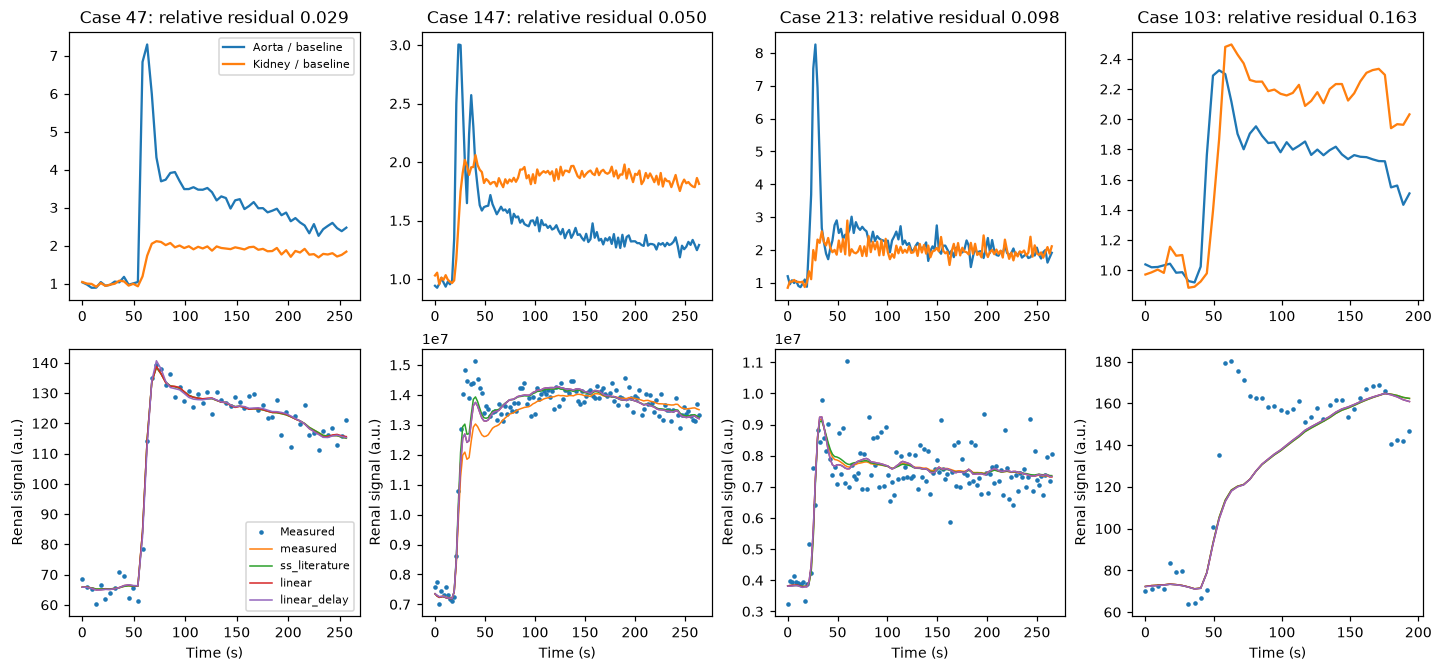

In [4]:
original=up['upstream_parameters'][0]
fig,axes=plt.subplots(1,4,figsize=(13,3.2),layout='constrained')
labels=['Plasma flow (mL/s/mL)','Plasma volume fraction','Filtration ratio','Tubular transit (s)']
for j,ax in enumerate(axes):
 ax.scatter(original[:,j],p[:,j],s=9,alpha=.6);lo=min(original[:,j].min(),p[:,j].min());hi=max(original[:,j].max(),p[:,j].max());ax.plot([lo,hi],[lo,hi],'k--')
 ax.set(xlabel='Original '+labels[j],ylabel='Fresh local')
 if j==3:ax.set_xscale('log');ax.set_yscale('log')
plt.show()
err=np.array([np.linalg.norm(s[i,:L]-d['measurements'][0,i,:L])/np.linalg.norm(d['measurements'][0,i,:L]) for i,L in enumerate(d['lengths'][0])])
print('Primary parameter maximum absolute differences:',np.max(abs(p-original),axis=0))
print('Observed relative L2 residual median/max:',np.median(err),np.max(err))
chosen=[np.argmin(abs(err-np.quantile(err,q))) for q in [.1,.5,.9,1.]]
fig,axes=plt.subplots(2,4,figsize=(13,6),layout='constrained')
for col,i in enumerate(chosen):
 t,y,a,cal=case_data(d,int(i));axes[0,col].plot(t,a/np.mean(a[:cal['n0']]),label='Aorta / baseline')
 axes[0,col].plot(t,y/np.mean(y[:cal['n0']]),label='Kidney / baseline');axes[0,col].set_title(f'Case {i}: relative residual {err[i]:.3f}')
 axes[1,col].plot(t,y,'o',ms=2,label='Measured')
 for name,result in variants.items():axes[1,col].plot(t,result['signal'][0,i,:len(t)],lw=1,label=name)
 axes[1,col].set(xlabel='Time (s)',ylabel='Renal signal (a.u.)')
axes[0,0].legend(fontsize=7);axes[1,0].legend(fontsize=7);plt.show()

## Clinical comparison, without recalibration to isotope targets
Derived MRI GFR is compared against independent radionuclide measurements. This checks practical error rather than parameter-code fidelity. Bias, dispersion, RMSE and P30 (fraction within 30% of isotope GFR) use the same complete cohort and physical scale; no fitted bias correction is applied.

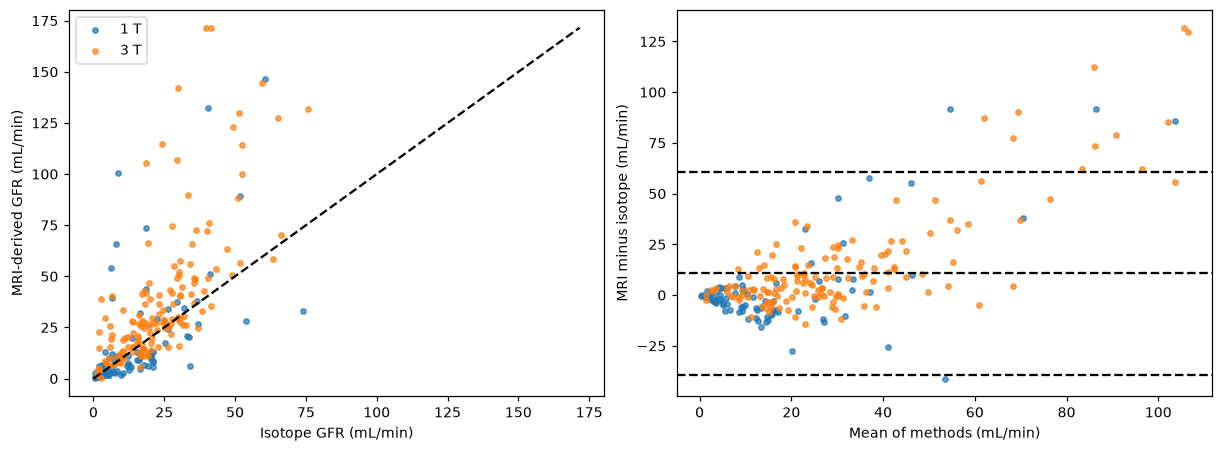

| Model | Bias mL/min | SD mL/min | RMSE mL/min | P30 |
|---|---:|---:|---:|---:|
|measured|10.693|25.439|27.595|32.5%|
|ss_literature|5.645|21.069|21.813|42.5%|
|linear|5.675|22.067|22.785|41.7%|
|linear_delay|6.047|21.509|22.343|43.0%|

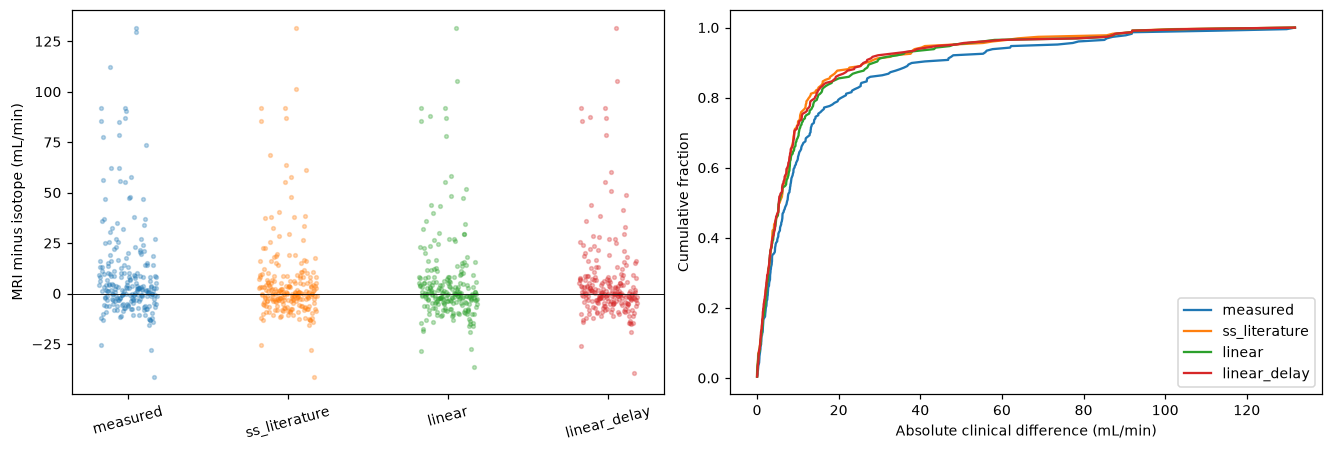

In [5]:
isotope=up['isotope_gfr_source'][0]*60
gfr={name:60*r['reconstruction'][0,:,-4]*r['reconstruction'][0,:,-2]*d['volume'][0] for name,r in variants.items()}
bland_altman(gfr['measured'],isotope,field);plt.show()
rows=['| Model | Bias mL/min | SD mL/min | RMSE mL/min | P30 |','|---|---:|---:|---:|---:|']
for name,g in gfr.items():
 q=clinical_statistics(g,isotope);rows.append(f"|{name}|{q['bias']:.3f}|{q['sd']:.3f}|{q['rmse']:.3f}|{q['p30']:.1%}|")
display(Markdown('\n'.join(rows)))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for k,(name,g) in enumerate(gfr.items()):
 axes[0].scatter(np.full(len(g),k)+np.linspace(-.18,.18,len(g)),g-isotope,s=6,alpha=.3)
 axes[1].plot(np.sort(abs(g-isotope)),np.arange(1,len(g)+1)/len(g),label=name)
axes[0].set_xticks(range(4),list(gfr),rotation=15);axes[0].set_ylabel('MRI minus isotope (mL/min)');axes[0].axhline(0,color='k',lw=.6)
axes[1].set(xlabel='Absolute clinical difference (mL/min)',ylabel='Cumulative fraction');axes[1].legend();plt.show()

## Field strength, repeat visits and failure diagnostics
Group comparisons are descriptive: acquisition groups and repeat visits are not randomized treatment groups. Long transit estimates can exceed acquisition duration by orders of magnitude. An optimizer returning finite values does not establish identifiability.

| Subgroup | N kidneys | GFR bias mL/min | P30 |
|---|---:|---:|---:|
|1 T|82|3.007|20.7%|
|3 T|146|15.010|39.0%|
|pre|194|10.448|33.0%|
|post|34|12.093|29.4%|

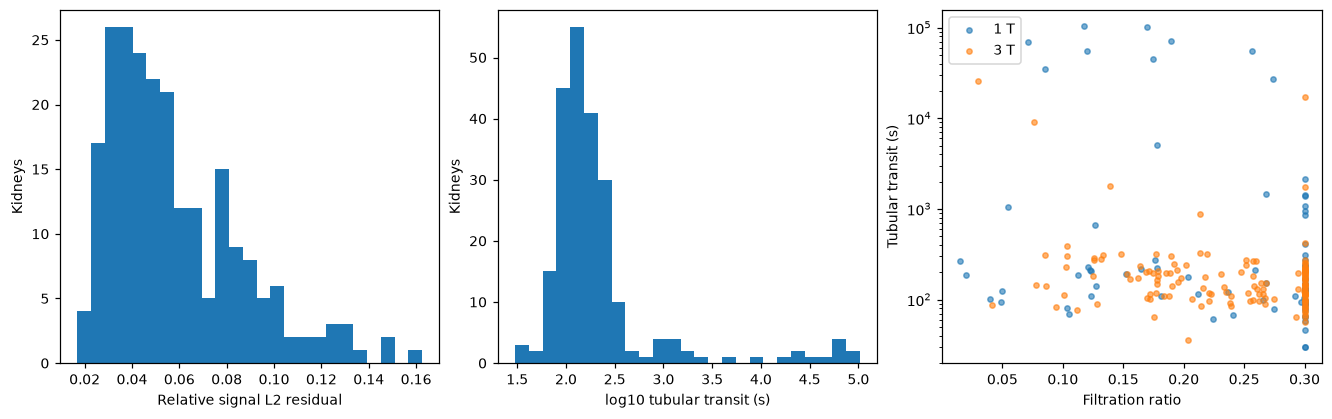

Transit >10000 s: 11 range: 30.000000000006903 103691.48335315307
At upper bounds Fp/vp/f (relative tolerance 1e-4): [21 52 96]


In [6]:
rows=['| Subgroup | N kidneys | GFR bias mL/min | P30 |','|---|---:|---:|---:|']
for label,m in [('1 T',field==1),('3 T',field==3),('pre',ids[:,1]==0),('post',ids[:,1]==1)]:
 q=clinical_statistics(gfr['measured'][m],isotope[m]);rows.append(f"|{label}|{m.sum()}|{q['bias']:.3f}|{q['p30']:.1%}|")
display(Markdown('\n'.join(rows)))
fig,axes=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
axes[0].hist(err,bins=25);axes[0].set(xlabel='Relative signal L2 residual',ylabel='Kidneys')
axes[1].hist(np.log10(p[:,3]),bins=25);axes[1].set(xlabel='log10 tubular transit (s)',ylabel='Kidneys')
for f in [1,3]:
 m=field==f;axes[2].scatter(p[m,2],p[m,3],s=12,alpha=.6,label=f'{f} T')
axes[2].set(xlabel='Filtration ratio',ylabel='Tubular transit (s)',yscale='log');axes[2].legend();plt.show()
print('Transit >10000 s:',int(np.sum(p[:,3]>10000)),'range:',p[:,3].min(),p[:,3].max())
print('At upper bounds Fp/vp/f (relative tolerance 1e-4):',np.sum(p[:,:3]>UPPER[:3]*(1-1e-4),axis=0))

## Active identifiability profile on measured curves
For the longest-transit case and a representative moderate-transit case, fix transit across a logarithmic grid and reoptimize the other three parameters. This is a fresh diagnostic experiment using the measured observations, not a simulated replacement dataset. Nearly flat residual profiles indicate that long transit times cannot be reliably resolved.

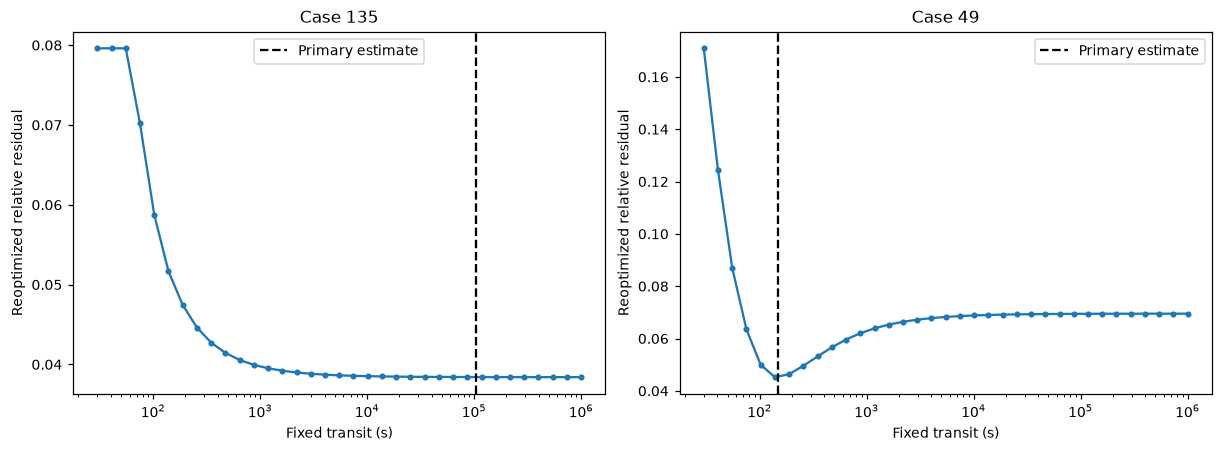

In [7]:
examples=[int(np.argmax(p[:,3])),int(np.argmin(abs(p[:,3]-np.median(p[:,3]))))]
grid=np.geomspace(30,1e6,35);fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,i in zip(axes,examples):
 t,y,a,cal=case_data(d,i);dd=diag[i];profile=[]
 for transit in grid:
  def residual(q):return predict(np.r_[q,transit],t,dd['arterial_concentration'],cal,dd['scale'])[0]-y
  q=least_squares(residual,p[i,:3],bounds=(LOWER[:3],UPPER[:3]));profile.append(np.linalg.norm(q.fun)/np.linalg.norm(y))
 ax.semilogx(grid,profile,'o-',ms=3);ax.axvline(p[i,3],color='k',ls='--',label='Primary estimate');ax.set(title=f'Case {i}',xlabel='Fixed transit (s)',ylabel='Reoptimized relative residual');ax.legend()
plt.show()
np.savez_compressed(root/'notebooks/reference_outputs/cleaned.npz',**fresh)

## Total filtration and split renal function
The paper also compares total GFR (left plus right) and split renal function (left divided by total). All 114 scans have both kidneys. These derived comparisons preserve that scientific question on the available cohort; they do not recreate the paper's missing cases. Split function cancels common scale errors but can retain asymmetric errors. No isotope value is used to refit any model.

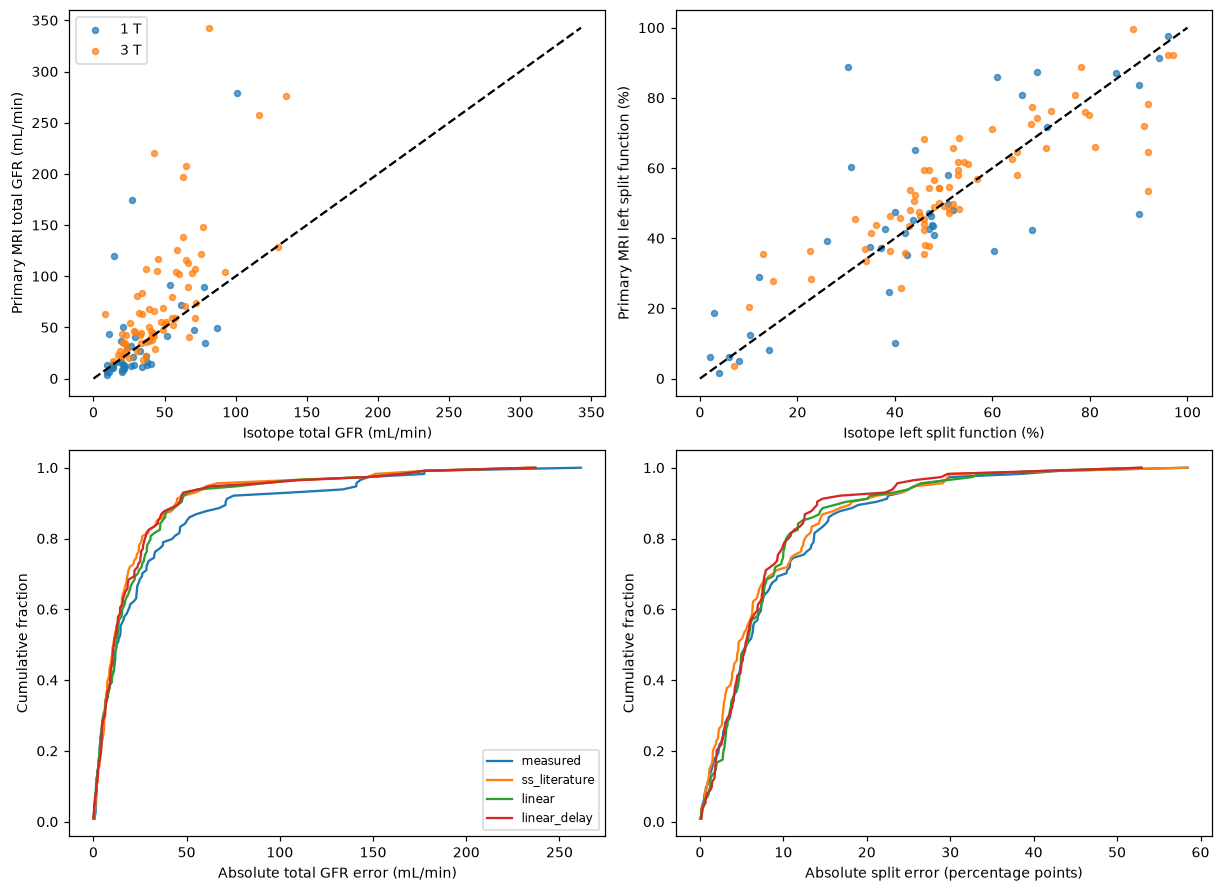

| Model | Total GFR bias (mL/min) | Total GFR RMSE (mL/min) | Total GFR P30 | Split bias (percentage points) | Split RMSE (percentage points) |
|---|---:|---:|---:|---:|---:|
|measured|21.386|52.520|36.8%|1.597|12.870|
|ss_literature|11.290|40.782|49.1%|2.125|12.223|
|linear|11.350|42.730|42.1%|0.894|11.835|
|linear_delay|12.094|42.080|43.9%|1.405|11.126|

In [8]:
assert np.all(ids[::2,:2]==ids[1::2,:2]) and np.all(ids[::2,2]==0) and np.all(ids[1::2,2]==1)
reference_total=isotope.reshape(-1,2).sum(axis=1)
reference_split=isotope[::2]/reference_total
rows=['| Model | Total GFR bias (mL/min) | Total GFR RMSE (mL/min) | Total GFR P30 | Split bias (percentage points) | Split RMSE (percentage points) |','|---|---:|---:|---:|---:|---:|']
fig,axes=plt.subplots(2,2,figsize=(11,8),layout='constrained')
for name,g in gfr.items():
 total=g.reshape(-1,2).sum(axis=1);split=g[::2]/total
 q=clinical_statistics(total,reference_total);e=100*(split-reference_split)
 rows.append(f"|{name}|{q['bias']:.3f}|{q['rmse']:.3f}|{q['p30']:.1%}|{np.mean(e):.3f}|{np.sqrt(np.mean(e**2)):.3f}|")
 axes[1,0].plot(np.sort(abs(total-reference_total)),np.arange(1,115)/114,label=name)
 axes[1,1].plot(np.sort(abs(e)),np.arange(1,115)/114,label=name)
 if name=='measured':
  for f in [1,3]:
   m=field[::2]==f;axes[0,0].scatter(reference_total[m],total[m],s=15,alpha=.7,label=f'{f} T');axes[0,1].scatter(100*reference_split[m],100*split[m],s=15,alpha=.7,label=f'{f} T')
  maximum=max(reference_total.max(),total.max());axes[0,0].plot([0,maximum],[0,maximum],'k--');axes[0,1].plot([0,100],[0,100],'k--')
axes[0,0].set(xlabel='Isotope total GFR (mL/min)',ylabel='Primary MRI total GFR (mL/min)');axes[0,0].legend()
axes[0,1].set(xlabel='Isotope left split function (%)',ylabel='Primary MRI left split function (%)')
axes[1,0].set(xlabel='Absolute total GFR error (mL/min)',ylabel='Cumulative fraction');axes[1,0].legend(fontsize=8)
axes[1,1].set(xlabel='Absolute split error (percentage points)',ylabel='Cumulative fraction')
plt.show();display(Markdown('\n'.join(rows)))

# Conclusion
The actively executed local implementation reproduces the selected original nonlinear inverse and preserves all four full-cohort comparisons. This establishes algorithm fidelity, not clinically accurate filtration or uniquely identified compartment parameters. Independent isotope comparisons show clinically important disagreement; extreme transit times and profile flatness expose weak washout identifiability.

The complete released cohort is retained, with no target-derived mask or retrospective isotope calibration. Limitations include processed ROI input rather than images, a smaller cohort than the historical paper, assumed haematocrit and relaxivity, missing tissue T1 replaced by literature values, and an isotope-unit metadata discrepancy handled explicitly using the author's executable convention.